# Three ways to make the likelihood cheaper

The likelihood of gravitational-wave data is a sum over many frequencies.
For long signals this sum has millions of terms.
This notebook illustrates the idea behind three methods that shorten it:

* **relative binning** (also called heterodyning);
* **multibanding**;
* **reduced-order quadrature (ROQ)**.

All three panels use a simple inspiral waveform. They explain the ideas; they are not implementations of the methods.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from gwr_style import COLORS, TEXTWIDTH, save_figure

## A simple waveform

In the frequency domain, the leading-order inspiral waveform is

$$\tilde h(f) \propto f^{-7/6}\, e^{i\Psi(f)}, \qquad
\Psi(f) = \frac{3}{128}\left(\frac{\pi G \mathcal{M}_d f}{c^3}\right)^{-5/3},$$

where $\mathcal{M}_d$ is the detector-frame chirp mass. The phase $\Psi$ is large, so the waveform oscillates quickly with frequency.

In [2]:
G_MSUN_C3 = 4.925491e-6  # G * (one solar mass) / c^3, in seconds


def waveform(f, chirp_mass):
    """Leading-order inspiral waveform (complex), with arbitrary normalization."""
    phase = 3.0 / 128.0 * (np.pi * G_MSUN_C3 * chirp_mass * f) ** (-5.0 / 3.0)
    return f ** (-7.0 / 6.0) * np.exp(1j * phase)


def time_to_merger(f, chirp_mass):
    """Time left before merger in seconds, at gravitational-wave frequency f."""
    return 5.0 / 256.0 * (G_MSUN_C3 * chirp_mass) ** (-5.0 / 3.0) * (np.pi * f) ** (-8.0 / 3.0)

## Panel 1: relative binning

Take a reference waveform $h_0$ and a second waveform $h$ with a slightly different chirp mass.
Both oscillate quickly. Their **ratio** $h/h_0$ does not: it is a smooth function of frequency.
A smooth function can be described with a few straight segments.

In [3]:
f_rb = np.linspace(20, 60, 4000)
h_reference = waveform(f_rb, chirp_mass=30.0)
h_other = waveform(f_rb, chirp_mass=30.0 * 1.02)  # chirp mass 2% larger
ratio = h_other / h_reference

# Edges of the frequency bins, and the ratio evaluated only there
bin_edges = np.linspace(20, 60, 9)
ratio_at_edges = waveform(bin_edges, 30.0 * 1.02) / waveform(bin_edges, 30.0)

## Panel 2: multibanding

A frequency resolution $\Delta f$ can describe a signal that lasts at most $1/\Delta f$.
The part of the signal above a frequency $f$ lasts only $\tau(f)$, the time to merger.
So at frequency $f$ a resolution $\Delta f = 1/\tau(f)$ is enough.
Multibanding splits the frequency range into bands, each with the coarsest resolution allowed.

In [4]:
mc_bns = 1.2188  # chirp mass of a 1.4 + 1.4 solar-mass binary
f_mb = np.geomspace(5, 1024, 500)
allowed_resolution = 1.0 / time_to_merger(f_mb, mc_bns)

# Bands: every time the allowed resolution doubles, start a new band.
# Inside a band we use the resolution allowed at its lower edge.
uniform_resolution = 1.0 / time_to_merger(5.0, mc_bns)  # needed without multibanding
band_edges = [5.0]
band_resolutions = [uniform_resolution]
while band_edges[-1] < 1024:
    next_resolution = band_resolutions[-1] * 2.0
    # frequency at which 1 / tau(f) equals next_resolution
    next_edge = np.interp(next_resolution, allowed_resolution, f_mb)
    if next_edge >= 1024 or next_resolution > allowed_resolution[-1]:
        break
    band_edges.append(next_edge)
    band_resolutions.append(next_resolution)
band_edges.append(1024.0)

## Panel 3: reduced-order quadrature

ROQ replaces the sum over all frequencies with a sum over a small set of special frequencies.
The waveform is computed only there.
In a real ROQ these frequencies are selected by an algorithm when the basis is built.
Here we simply place 16 points by hand, to show how few they are compared with the full grid.

In [5]:
f_roq = np.linspace(20, 60, 4000)
h_roq = waveform(f_roq, chirp_mass=30.0)
node_frequencies = np.geomspace(20.5, 59.0, 16)
h_at_nodes = waveform(node_frequencies, chirp_mass=30.0)

# All curves in panels 1 and 3 are divided by this number, to keep them of order one
scale = np.abs(h_reference).max()

## The figure

Figure saved to output/fig_likelihood_methods.pdf


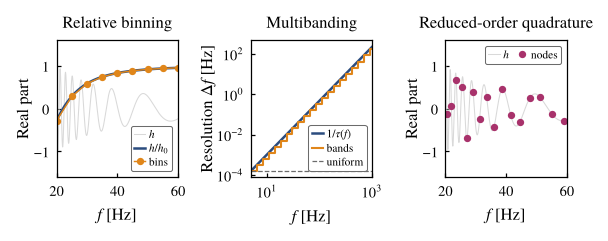

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(TEXTWIDTH, 0.27 * TEXTWIDTH), gridspec_kw={"wspace": 0.6})
legend_style = dict(fontsize=5.5, handlelength=1.0, handletextpad=0.3, borderpad=0.3, labelspacing=0.2)

# Panel 1: relative binning
ax = axes[0]
ax.plot(f_rb, h_other.real / scale, color=COLORS["lightgrey"], lw=0.5, label=r"$h$")
ax.plot(f_rb, ratio.real, color=COLORS["blue"], label=r"$h/h_0$")
ax.plot(bin_edges, ratio_at_edges.real, "o-", color=COLORS["orange"], ms=2.5, lw=0.7, label="bins")
ax.set_xlabel("$f$ [Hz]")
ax.set_ylabel("Real part", labelpad=1)
ax.set_title("Relative binning")
ax.set_xlim(20, 60)
ax.set_ylim(-1.6, 1.6)
ax.legend(loc="lower right", **legend_style)

# Panel 2: multibanding
ax = axes[1]
ax.loglog(f_mb, allowed_resolution, color=COLORS["blue"], label=r"$1/\tau(f)$")
# a step line: inside each band the resolution is constant
ax.step(band_edges, band_resolutions + [band_resolutions[-1]], where="post", color=COLORS["orange"], lw=1.0, label="bands")
ax.axhline(uniform_resolution, color=COLORS["grey"], lw=0.6, ls="--", label="uniform")
ax.set_xlabel("$f$ [Hz]")
ax.set_ylabel(r"Resolution $\Delta f$ [Hz]", labelpad=0)
ax.set_title("Multibanding")
ax.set_xlim(5, 1024)
ax.legend(loc="lower right", **legend_style)

# Panel 3: reduced-order quadrature
ax = axes[2]
ax.plot(f_roq, h_roq.real / scale, color=COLORS["lightgrey"], lw=0.5, label=r"$h$")
ax.plot(node_frequencies, h_at_nodes.real / scale, "o", color=COLORS["magenta"], ms=2.5, label="nodes")
ax.set_xlabel("$f$ [Hz]")
ax.set_ylabel("Real part", labelpad=1)
ax.set_title("Reduced-order quadrature")
ax.set_xlim(20, 60)
ax.set_ylim(-1.6, 1.6)
ax.legend(loc="upper right", ncol=2, columnspacing=0.6, **legend_style)

for ax in axes:
    ax.tick_params(length=2)

save_figure(fig, "fig_likelihood_methods.pdf")
plt.show()